# Linear PCA versus Kernel PCA

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.decomposition import KernelPCA, PCA

# A function that simply returns its input as a coordinate tuple
def identity_transform(X):
    return X

# Plot grid lines as points so we can later show the deformation of the feature space
def plot_grid(xmin, xmax, ymin, ymax, transform=identity_transform, n=10, line_density=1000):
    xxh, yyh = np.meshgrid(np.linspace(xmin, xmax, line_density), np.linspace(ymin, ymax, n))
    xxv, yyv = np.meshgrid(np.linspace(xmin, xmax, n), np.linspace(ymin, ymax, line_density))
    Z = np.vstack([
        transform(np.c_[xxh.ravel(), yyh.ravel()]),
        transform(np.c_[xxv.ravel(), yyv.ravel()])
    ])
    plt.scatter(Z[:, 0], Z[:, 1], s=1, c='black', alpha=0.1)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


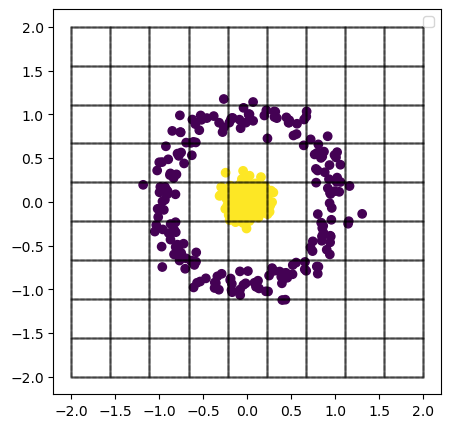

In [2]:
# Create a dataset with circle structure
X, y = make_circles(n_samples=400, noise=0.1, random_state=42, factor=0.1)

# Visualize the dataset
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y)

plot_grid(-2, 2, -2, 2)
plt.legend()
plt.show()


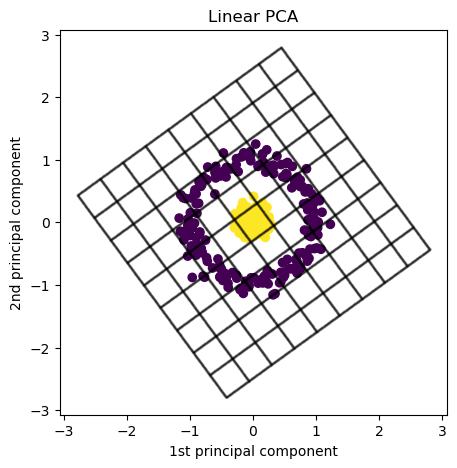

In [3]:
# Apply Linear PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Visualize the transformed dataset
plt.figure(figsize=(5, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plot_grid(-2, 2, -2, 2, transform=pca.transform)
plt.title("Linear PCA")
plt.xlabel("1st principal component")
plt.ylabel("2nd principal component")
plt.show()

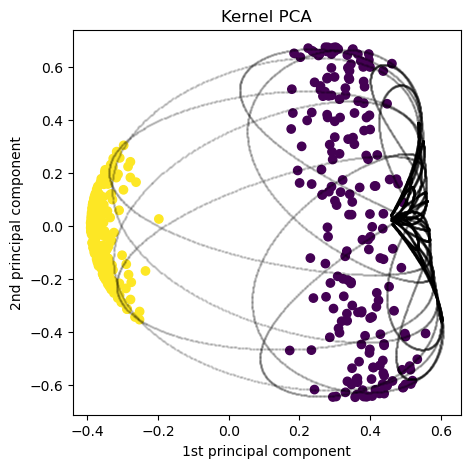

In [4]:
# Apply Kernel PCA
# Add y as a feature to the dataset
kpca = KernelPCA(kernel="rbf", gamma=1, n_components=2)
X_kpca = kpca.fit_transform(X)

# Visualize the transformed dataset
plt.figure(figsize=(5, 5))
plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y)
plot_grid(-2, 2, -2, 2, transform=kpca.transform)
plt.title("Kernel PCA")
plt.xlabel("1st principal component")
plt.ylabel("2nd principal component")
plt.show()

# PCA and KernelPCA are unsupervised learning algorithms!

It is important to note that PCA and KernelPCA are unsupervised learning algorithms, and therefore do not consider the class labels at all.
In the following, we show that for a slightly modified version of the dataset, the KernelPCA algorithm is not able to separate the two classes anymore.

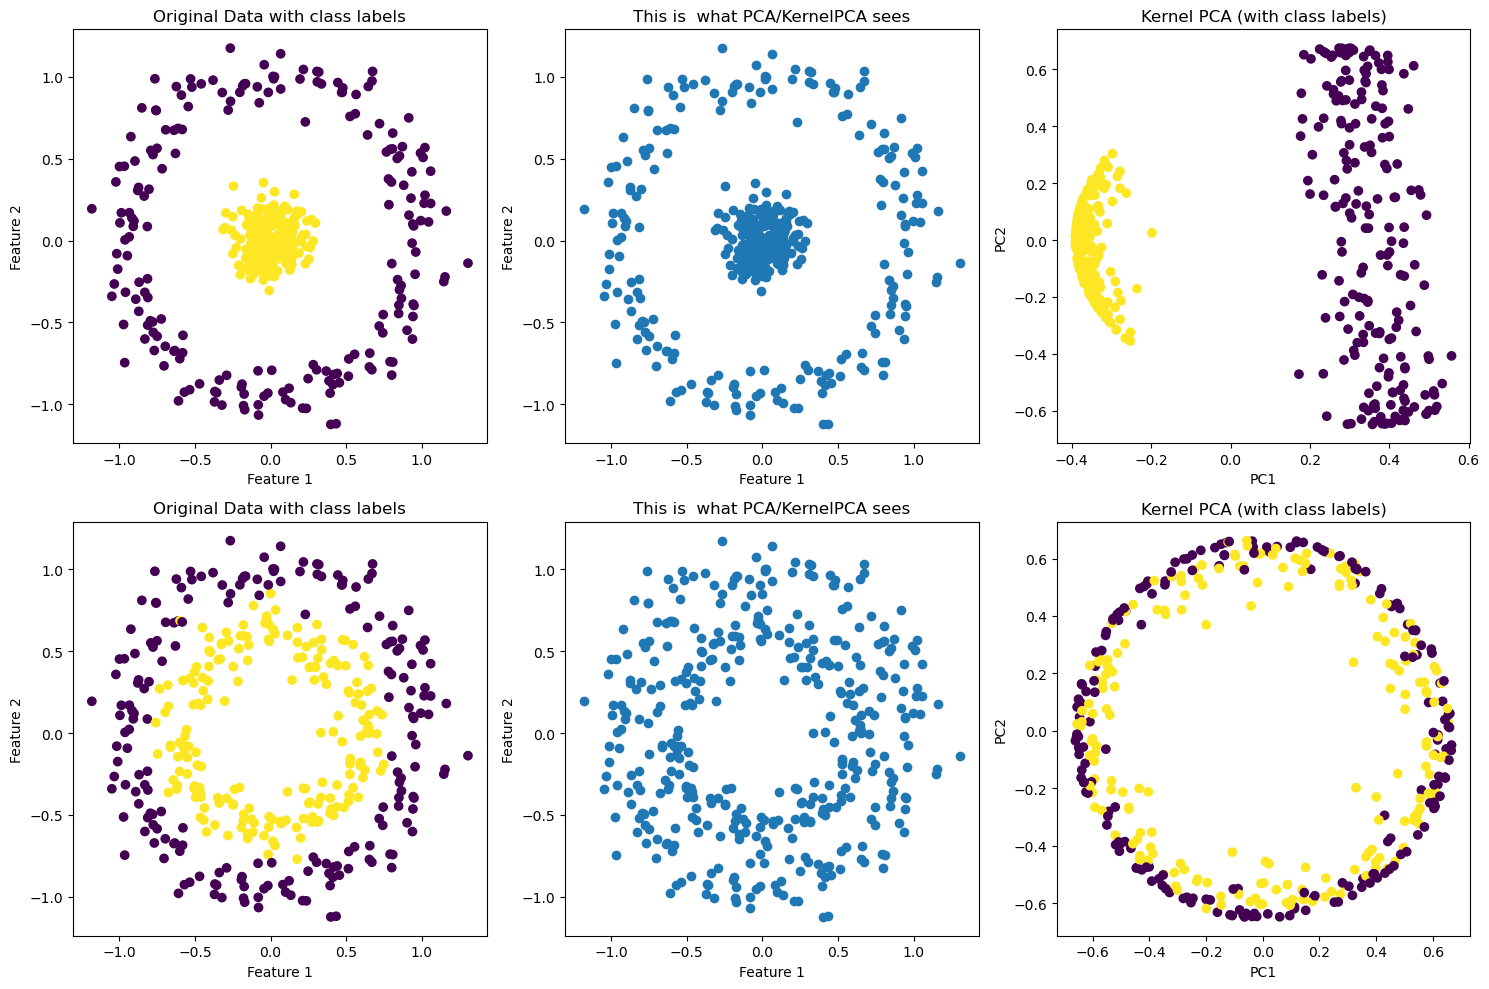

In [5]:
# Create a dataset with 100 samples in circles
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for factor, ax in zip((0.1, 0.6), axes):
    X, y = make_circles(n_samples=400, noise=0.1, random_state=42, factor=factor)

    # Apply KernelPCA
    kpca = KernelPCA(n_components=2, kernel="rbf", gamma=1)
    X_kpca = kpca.fit_transform(X)

    # Plot the results
    ax[0].scatter(X[:, 0], X[:, 1], c=y)
    ax[0].set_title('Original Data with class labels')
    ax[0].set_xlabel('Feature 1')
    ax[0].set_ylabel('Feature 2')

    ax[1].scatter(X[:, 0], X[:, 1])
    ax[1].set_title('This is what PCA/KernelPCA sees')
    ax[1].set_xlabel('Feature 1')
    ax[1].set_ylabel('Feature 2')

    ax[2].scatter(X_kpca[:, 0], X_kpca[:, 1], c=y)
    ax[2].set_title('Kernel PCA (with class labels)')
    ax[2].set_xlabel('PC1')
    ax[2].set_ylabel('PC2')

fig.tight_layout()
plt.show()
